--- Dataset Shape ---
(284807, 31)

--- Class Distribution ---
Normal Transactions (0): 284315 (99.827%)
Fraudulent Transactions (1): 492 (0.173%)


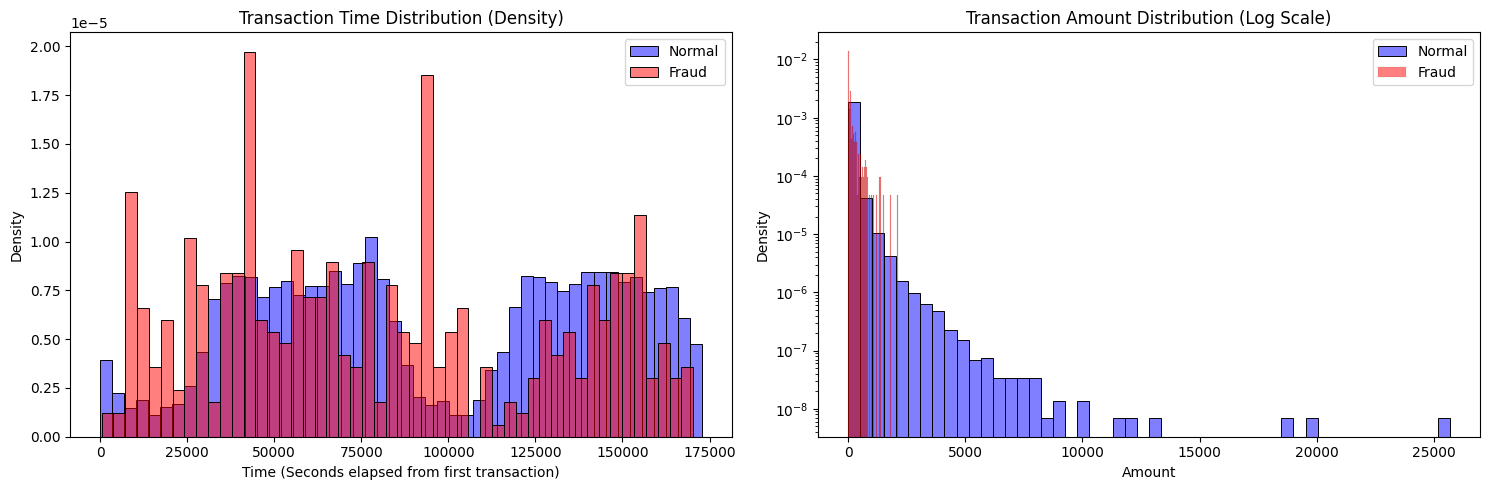

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('creditcard.csv')

print("--- Dataset Shape ---")
print(df.shape)

# 2. Analyze class imbalance
fraud_counts = df['Class'].value_counts()
fraud_percentage = (fraud_counts / len(df)) * 100

print("\n--- Class Distribution ---")
print(f"Normal Transactions (0): {fraud_counts[0]} ({fraud_percentage[0]:.3f}%)")
print(f"Fraudulent Transactions (1): {fraud_counts[1]} ({fraud_percentage[1]:.3f}%)")

# 3. EDA: Transaction Time and Amount Distributions
plt.figure(figsize=(15, 5))

# Time distribution (Fraud vs Normal)
plt.subplot(1, 2, 1)
sns.histplot(df[df['Class'] == 0]['Time'], bins=50, color='blue', alpha=0.5, label='Normal', stat='density')
sns.histplot(df[df['Class'] == 1]['Time'], bins=50, color='red', alpha=0.5, label='Fraud', stat='density')
plt.title('Transaction Time Distribution (Density)')
plt.xlabel('Time (Seconds elapsed from first transaction)')
plt.legend()

# Amount distribution (Fraud vs Normal)
# Using log scale for the Y-axis because the amounts are heavily skewed
plt.subplot(1, 2, 2)
sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, color='blue', alpha=0.5, label='Normal', stat='density')
sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, color='red', alpha=0.5, label='Fraud', stat='density')
plt.title('Transaction Amount Distribution (Log Scale)')
plt.xlabel('Amount')
plt.yscale('log')
plt.legend()

plt.tight_layout()
plt.show()

**Observation: Class Imbalance & Metric Selection**
* **The Accuracy Trap:** Because 99.83% of transactions in this dataset are normal, a "dumb" model that simply predicts "Normal" every single time would achieve 99.83% accuracy. However, it would catch zero actual frauds, making it completely useless for the business.
* **Better Metrics:** For fraud detection, standard accuracy is misleading. We must prioritize **Recall** (to catch as many actual frauds as possible) and use metrics like the **F1-Score** and **Precision-Recall AUC**, which properly penalize models that fail to identify the minority class.

In [2]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Separate features (X) and target (y)
X = df.drop('Class', axis=1)
y = df['Class']

# 1. Train/Test Split
# Using stratify=y ensures the 0.17% fraud ratio is preserved in both the training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("--- Class Distribution Before SMOTE (Training Set) ---")
print(y_train.value_counts())

# 2. Apply SMOTE (Synthetic Minority Over-sampling Technique)
# CRITICAL: Only apply SMOTE to the training data to prevent data leakage into the test set
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\n--- Class Distribution After SMOTE (Training Set) ---")
print(y_train_smote.value_counts())

--- Class Distribution Before SMOTE (Training Set) ---
Class
0    227451
1       394
Name: count, dtype: int64


C:\Users\dp185\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\dp185\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 554, in run
    


--- Class Distribution After SMOTE (Training Set) ---
Class
0    227451
1    227451
Name: count, dtype: int64


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

# 1. Train Logistic Regression
print("Training Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_smote, y_train_smote)
lr_preds = lr_model.predict(X_test)
lr_probs = lr_model.predict_proba(X_test)[:, 1]

# 2. Train Random Forest (Optimized with n_jobs=-1 to use all CPU cores)
print("Training Random Forest...")
rf_model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# 3. Output Evaluations
print("\n--- Logistic Regression Evaluation ---")
print(classification_report(y_test, lr_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_probs):.4f}")

print("\n--- Random Forest Evaluation ---")
print(classification_report(y_test, rf_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_probs):.4f}")

Training Logistic Regression...


C:\Users\dp185\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Random Forest...

--- Logistic Regression Evaluation ---
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.13      0.90      0.22        98

    accuracy                           0.99     56962
   macro avg       0.56      0.94      0.61     56962
weighted avg       1.00      0.99      0.99     56962

ROC-AUC Score: 0.9766

--- Random Forest Evaluation ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.51      0.89      0.65        98

    accuracy                           1.00     56962
   macro avg       0.76      0.94      0.83     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9853


**Observation: The Precision vs. Recall Trade-off**
* **Why Recall Wins:** In fraud detection, **Recall** is the most critical metric. The Random Forest model achieved a Recall of 0.89, meaning it successfully caught 89% of all actual fraudulent transactions. 
* **The Cost of Precision:** The model's Precision is 0.51, meaning that when it flags a transaction as fraud, it is only correct 51% of the time (the other 49% are False Positives). In banking, this trade-off is acceptable: the financial cost of missing a fraudulent charge (False Negative) is vastly higher than the minor inconvenience of texting a customer to verify a legitimate purchase (False Positive).

**Scalability: Handling 1 Million Transactions per Hour**
To scale this model for 1 million transactions per hour in a production environment:
1. **Model Selection:** Random Forest is highly accurate but computationally heavy. We would likely deploy a faster gradient boosting model (like XGBoost or LightGBM) or optimize the Random Forest by reducing tree depth.
2. **Infrastructure:** The model must be deployed as a microservice (e.g., via Docker and Kubernetes) behind a load balancer, utilizing distributed streaming platforms like Apache Kafka to process incoming transaction queues in real time.

C:\Users\dp185\AppData\Local\Temp\ipykernel_35868\1861827437.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_df.head(15), x='Importance', y='Feature', palette='Reds_r')


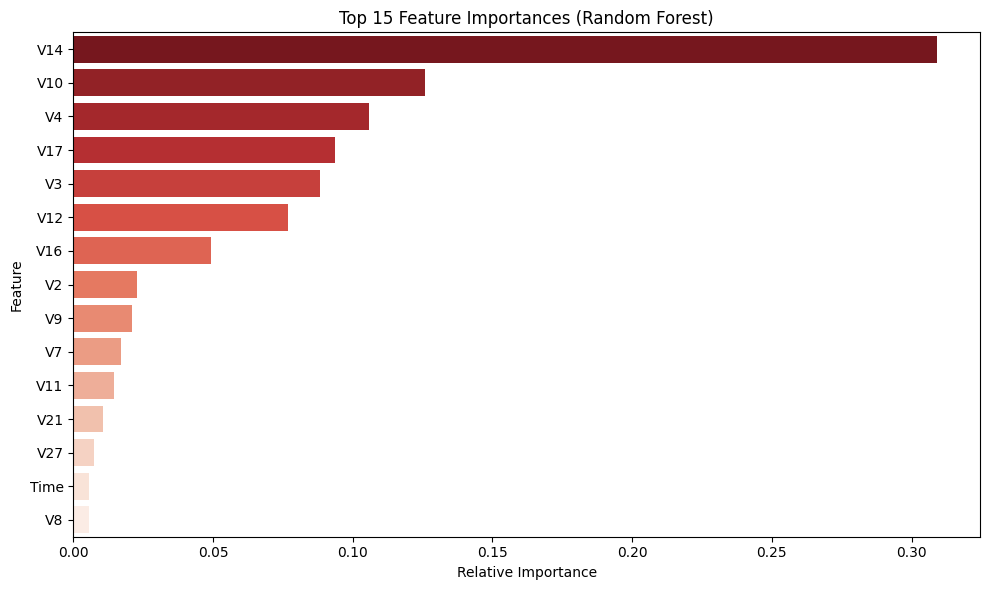

In [5]:
# Extract feature importances from the Random Forest model
importances = rf_model.feature_importances_
feature_names = X.columns

# Create a DataFrame and sort by importance
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the top 15 most important features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(15), x='Importance', y='Feature', palette='Reds_r')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()